# Generación — Notebook 02
## Modelo de difusión latente (arquitectura Stable Diffusion) con 🤗 diffusers y *fine-tuning* LoRA

**Stable Diffusion** (Rombach et al., 2022) es un **modelo de difusión latente (LDM)** formado por tres redes:

| Componente | Función | En Stable Diffusion 1.5 | En este notebook (mini-SD) |
|---|---|---|---|
| **VAE** (`AutoencoderKL`) | Comprime la imagen a un **espacio latente** y la reconstruye | 512×512×3 → 64×64×4 (48× menos valores) | 32×32×1 → 8×8×4 (4×) |
| **Codificador de texto** (`CLIPTextModel`) | Convierte el *prompt* en vectores que condicionan la generación | CLIP ViT-L/14, 123 M | CLIP de 2 capas a nivel de caracteres |
| **U-Net condicional** (`UNet2DConditionModel`) | Predice el ruido presente en el latente; atiende al texto con *cross-attention* | 860 M | ≈ 0.8 M |
| **Scheduler** (`DDPMScheduler` / `DDIMScheduler`) | Define el proceso de ruido y el muestreo | 1000 pasos, β *scaled_linear* | Igual |

Como el entorno de trabajo no tiene GPU ni acceso a Hugging Face Hub, no es posible descargar ni entrenar SD 1.5 aquí. Por eso este notebook **construye con las mismas clases de `diffusers` una Stable Diffusion en miniatura**, la pre-entrena y luego le aplica **exactamente el mismo procedimiento de fine-tuning LoRA** que se usa con SD 1.5 (script oficial `train_text_to_image_lora.py`):

1. **Pre-entrenamiento** (equivale al modelo base que publica Stability AI): VAE + texto + U-Net sobre **Fashion-MNIST** con descripciones como «foto de una zapatilla».
2. **Fine-tuning LoRA** (lo que hace un usuario con SD): se congela todo y se añaden adaptadores LoRA a la atención de la U-Net para enseñar un **concepto nuevo** que el modelo base nunca vio: «foto de un rostro» (base ORL).

El Notebook 03 contiene la versión para SD 1.5 real, lista para ejecutarse en Colab con GPU.

In [1]:
import os, json, time, math, gzip, urllib.request, warnings
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import diffusers, transformers, peft
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, DDIMScheduler, StableDiffusionPipeline
from diffusers.utils import logging as dlog
from transformers import CLIPTokenizer, CLIPTextModel, CLIPTextConfig
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
dlog.set_verbosity_error(); transformers.logging.set_verbosity_error()

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for d in ("data", "figures", "results", "modelos"): os.makedirs(d, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})
print(f"diffusers {diffusers.__version__} | transformers {transformers.__version__} | peft {peft.__version__} | PyTorch {torch.__version__} | {device}")

diffusers 0.43.0 | transformers 5.24.1 | peft 0.22.0 | PyTorch 2.15.0+cu132 | cpu


## 1. Preparación de los datos
* **Pre-entrenamiento:** Fashion-MNIST (Zalando Research), 2 000 imágenes por clase (20 000 en total), con su descripción en español.
* **Fine-tuning:** 200 rostros de la base ORL/AT&T (20 personas × 10 fotos), con la descripción «foto de un rostro».

Todas las imágenes se llevan a 32×32 en escala de grises y a [−1, 1].

Fashion-MNIST: (20000, 1, 32, 32) | rostros fine-tuning: (200, 1, 32, 32) | rostros evaluación: (200, 1, 32, 32)


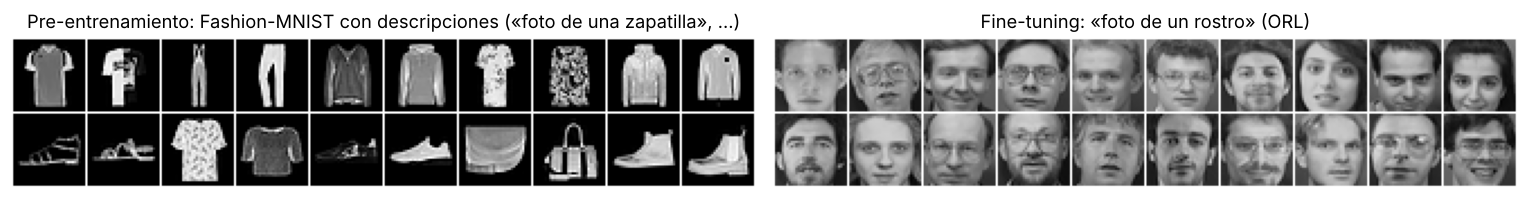

In [2]:
CLASES = ["una camiseta", "un pantalón", "un suéter", "un vestido", "un abrigo",
          "una sandalia", "una camisa", "una zapatilla", "un bolso", "un botín"]
FM = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion"
for f in ("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"):
    if not os.path.exists(f"data/{f}"): urllib.request.urlretrieve(f"{FM}/{f}", f"data/{f}")
imgs = np.frombuffer(gzip.open("data/train-images-idx3-ubyte.gz").read(), np.uint8, offset=16).reshape(-1, 28, 28)
labs = np.frombuffer(gzip.open("data/train-labels-idx1-ubyte.gz").read(), np.uint8, offset=8)
rng = np.random.default_rng(SEED)
idx = np.concatenate([rng.choice(np.where(labs == c)[0], 2000, replace=False) for c in range(10)])
fm_x = torch.tensor(np.pad(imgs[idx], ((0, 0), (2, 2), (2, 2))), dtype=torch.float32)[:, None] / 127.5 - 1   # 28 -> 32
fm_y = torch.tensor(labs[idx].astype(np.int64))
fm_txt = [f"foto de {CLASES[c]}" for c in fm_y.tolist()]

ORL = "https://raw.githubusercontent.com/milk-abc/PCA-KPCA/master/att_faces"
jobs = [(f"{ORL}/s{s}/{i}.pgm", f"data/orl/s{s}/{i}.pgm") for s in range(1, 41) for i in range(1, 11)]
for _, dst in jobs: os.makedirs(os.path.dirname(dst), exist_ok=True)
with ThreadPoolExecutor(16) as ex: list(ex.map(lambda j: None if os.path.exists(j[1]) else urllib.request.urlretrieve(*j), jobs))
def load_face(p, size=32):
    return np.asarray(Image.open(p).crop((0, 10, 92, 102)).resize((size, size), Image.LANCZOS), dtype=np.float32) / 127.5 - 1
faces_all = torch.tensor(np.stack([load_face(f"data/orl/s{s}/{i}.pgm") for s in range(1, 41) for i in range(1, 11)]))[:, None]
face_ft, face_test = faces_all[:200], faces_all[200:]            # personas 1-20: fine-tuning | 21-40: evaluación
print("Fashion-MNIST:", tuple(fm_x.shape), "| rostros fine-tuning:", tuple(face_ft.shape), "| rostros evaluación:", tuple(face_test.shape))

def grid(t, nrow=8, pad=1):
    t = ((t.detach().cpu().float().clamp(-1, 1) + 1) / 2)[:, 0]
    n, h, w = t.shape; rows = math.ceil(n / nrow)
    g = np.ones((rows * (h + pad) + pad, nrow * (w + pad) + pad))
    for k in range(n):
        r, c = divmod(k, nrow); g[pad + r * (h + pad): pad + r * (h + pad) + h, pad + c * (w + pad): pad + c * (w + pad) + w] = t[k].numpy()
    return g

fig, ax = plt.subplots(1, 2, figsize=(14, 2.8))
ax[0].imshow(grid(torch.cat([fm_x[fm_y == c][:2] for c in range(10)]), 10), cmap="gray"); ax[0].axis("off")
ax[0].set_title("Pre-entrenamiento: Fashion-MNIST con descripciones («foto de una zapatilla», …)")
ax[1].imshow(grid(face_ft[::10][:20], 10), cmap="gray"); ax[1].axis("off"); ax[1].set_title("Fine-tuning: «foto de un rostro» (ORL)")
plt.tight_layout(); plt.savefig("figures/02_datos.png", bbox_inches="tight"); plt.show()

## 2. Tokenizador y codificador de texto (CLIP)
Se usa la clase `CLIPTokenizer` de `transformers` con un vocabulario a **nivel de caracteres** (BPE sin fusiones) y un `CLIPTextModel` de 2 capas. Igual que en Stable Diffusion, la U-Net recibe la secuencia completa de estados ocultos del codificador (`last_hidden_state`) y la consulta mediante *cross-attention*. La palabra «rostro» **nunca aparece** en el pre-entrenamiento.

In [3]:
os.makedirs("modelos/tokenizer", exist_ok=True)
vocab = {"<|startoftext|>": 0, "<|endoftext|>": 1}
for ch in "abcdefghijklmnopqrstuvwxyzáéíóúñü0123456789":
    vocab[ch] = len(vocab); vocab[ch + "</w>"] = len(vocab)
json.dump(vocab, open("modelos/tokenizer/vocab.json", "w"), ensure_ascii=False)
open("modelos/tokenizer/merges.txt", "w").write("#version: 0.2\n")
MAXLEN = 32
tokenizer = CLIPTokenizer("modelos/tokenizer/vocab.json", "modelos/tokenizer/merges.txt", model_max_length=MAXLEN, pad_token="<|endoftext|>")
def tokenize(txts): return tokenizer(txts, padding="max_length", max_length=MAXLEN, truncation=True, return_tensors="pt").input_ids
ej = tokenize(["foto de un rostro"])[0]
print("«foto de un rostro» →", ej[:20].tolist(), "...")
text_encoder = CLIPTextModel(CLIPTextConfig(vocab_size=len(vocab), hidden_size=64, intermediate_size=128, num_hidden_layers=2,
                                            num_attention_heads=4, max_position_embeddings=MAXLEN, bos_token_id=0, eos_token_id=1, pad_token_id=1)).to(device)
print(f"CLIPTextModel: {sum(p.numel() for p in text_encoder.parameters()):,} parámetros | salida:", tuple(text_encoder(ej[None].to(device)).last_hidden_state.shape))

«foto de un rostro» → [0, 12, 30, 40, 31, 8, 11, 42, 29, 36, 30, 38, 40, 36, 31, 1, 1, 1, 1, 1] ...
CLIPTextModel: 74,752 parámetros | salida: (1, 32, 64)


## 3. VAE: compresión al espacio latente
El `AutoencoderKL` aprende a codificar cada imagen como una **distribución gaussiana** en el espacio latente (media y varianza) y a reconstruirla. En Stable Diffusion el VAE es un compresor **genérico** entrenado con millones de imágenes de todo tipo; para imitarlo, aquí se entrena con las prendas **y** con los 200 rostros de fine-tuning (repetidos 10 veces para equilibrar). El VAE sólo aprende a comprimir y reconstruir: el concepto «rostro» y su relación con el texto los aprende después la U-Net. La pérdida combina reconstrucción y una penalización KL muy pequeña (como en Stable Diffusion), que mantiene el latente cerca de una normal estándar sin sacrificar detalle. La difusión se hará luego **sobre estos latentes**, no sobre los píxeles: es la idea central de los *Latent Diffusion Models*.

AutoencoderKL: 241,749 parámetros


VAE época 1: L1 = 0.1665 (101 s)


VAE época 2: L1 = 0.0793 (160 s)


VAE época 3: L1 = 0.0689 (221 s)


VAE época 4: L1 = 0.0625 (282 s)


VAE época 5: L1 = 0.0593 (343 s)


Factor de escala del latente: 0.7721 | error medio de reconstrucción (0-255): prendas 6.8 | rostros de personas 21-40 (no vistas) 12.5


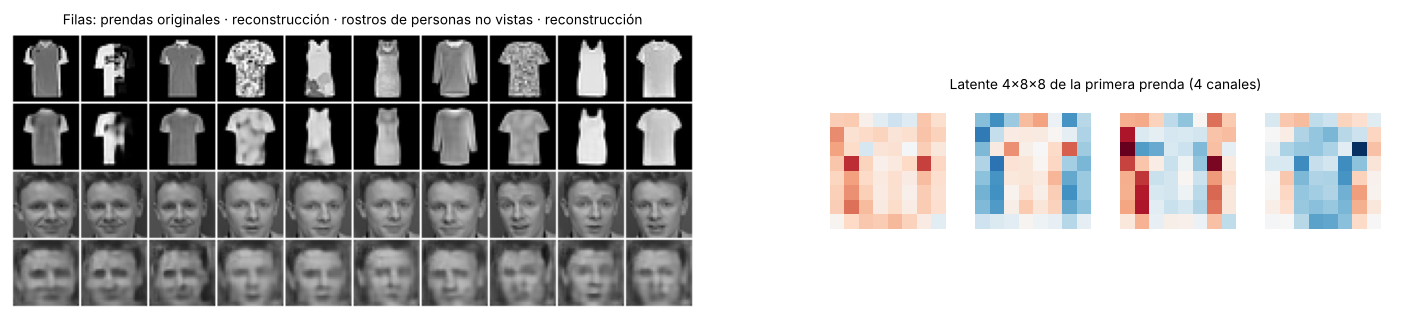

In [4]:
vae = AutoencoderKL(in_channels=1, out_channels=1, down_block_types=("DownEncoderBlock2D",) * 3, up_block_types=("UpDecoderBlock2D",) * 3,
                    block_out_channels=(16, 32, 32), latent_channels=4, layers_per_block=1, norm_num_groups=16, sample_size=32).to(device)
print(f"AutoencoderKL: {sum(p.numel() for p in vae.parameters()):,} parámetros")
opt = torch.optim.AdamW(vae.parameters(), lr=1e-3)
VAE_EPOCHS, BS = 5, 64
vae_x = torch.cat([fm_x, face_ft.repeat(10, 1, 1, 1)])
vae_hist, t0 = [], time.time()
for ep in range(VAE_EPOCHS):
    perm = torch.randperm(len(vae_x))
    for b in range(0, len(vae_x), BS):
        x = vae_x[perm[b:b + BS]].to(device)
        post = vae.encode(x).latent_dist
        rec = vae.decode(post.sample()).sample
        loss = F.l1_loss(rec, x) + 1e-6 * post.kl().mean()
        opt.zero_grad(); loss.backward(); opt.step(); vae_hist.append(loss.item())
    print(f"VAE época {ep + 1}: L1 = {np.mean(vae_hist[-len(vae_x) // BS:]):.4f} ({time.time() - t0:.0f} s)")
vae.eval(); vae.requires_grad_(False)

@torch.no_grad()
def encode(x, bs=256):
    return torch.cat([vae.encode(x[b:b + bs].to(device)).latent_dist.mean for b in range(0, len(x), bs)])

lat_fm = encode(fm_x)
SCALING = float(1.0 / lat_fm.std())          # SD 1.5 usa 0.18215 por la misma razón: latentes con varianza ≈ 1
vae.register_to_config(scaling_factor=SCALING)
with torch.no_grad():
    rec_fm = vae.decode(lat_fm[:10]).sample.cpu(); lat_face = encode(face_test[:10]); rec_face = vae.decode(lat_face).sample.cpu()
mae_fm = float((vae.decode(lat_fm[:1000]).sample.cpu() - fm_x[:1000]).abs().mean()) * 127.5
mae_face = float((vae.decode(encode(face_test)).sample.cpu() - face_test).abs().mean()) * 127.5
print(f"Factor de escala del latente: {SCALING:.4f} | error medio de reconstrucción (0-255): prendas {mae_fm:.1f} | rostros de personas 21-40 (no vistas) {mae_face:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.0), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].imshow(grid(torch.cat([fm_x[:10], rec_fm, face_test[:10], rec_face]), 10), cmap="gray"); ax[0].axis("off")
ax[0].set_title("Filas: prendas originales · reconstrucción · rostros de personas no vistas · reconstrucción", fontsize=9)
l = lat_fm[0].cpu()
ax[1].imshow(np.hstack([np.pad(c.numpy(), 1, constant_values=np.nan) for c in l]), cmap="RdBu"); ax[1].axis("off")
ax[1].set_title("Latente 4×8×8 de la primera prenda (4 canales)", fontsize=9)
plt.tight_layout(); plt.savefig("figures/02_vae.png", bbox_inches="tight"); plt.show()

## 4. Proceso de difusión hacia adelante
El *scheduler* define cómo se añade ruido gaussiano en T = 1000 pasos:

$$z_t = \sqrt{\bar\alpha_t}\, z_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\qquad \varepsilon \sim \mathcal{N}(0, I)$$

Con la planificación *scaled_linear* de Stable Diffusion (β de 0.00085 a 0.012), en t = 999 el latente es prácticamente ruido puro. La U-Net se entrena para **predecir ε** a partir de $z_t$, *t* y el texto.

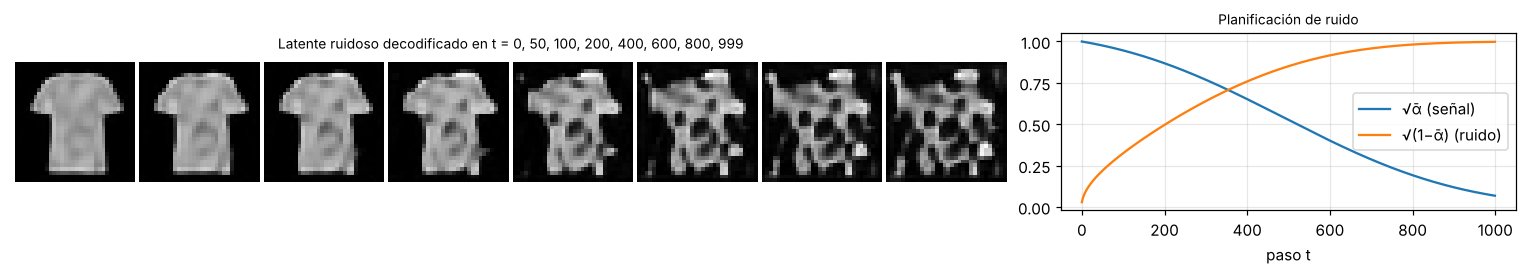

In [5]:
noise_scheduler = DDPMScheduler(num_train_timesteps=1000, beta_start=0.00085, beta_end=0.012, beta_schedule="scaled_linear")
z0 = lat_fm[7:8] * SCALING; eps = torch.randn_like(z0)
ts = [0, 50, 100, 200, 400, 600, 800, 999]
noisy = [noise_scheduler.add_noise(z0, eps, torch.tensor([t])) for t in ts]
with torch.no_grad():
    dec = torch.cat([vae.decode(n / SCALING).sample for n in noisy]).cpu()
fig, ax = plt.subplots(1, 2, figsize=(14, 2.6), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].imshow(grid(dec, 8), cmap="gray"); ax[0].axis("off"); ax[0].set_title("Latente ruidoso decodificado en t = " + ", ".join(map(str, ts)), fontsize=9)
ab = noise_scheduler.alphas_cumprod.numpy()
ax[1].plot(np.sqrt(ab), label="√ᾱ (señal)"); ax[1].plot(np.sqrt(1 - ab), label="√(1−ᾱ) (ruido)"); ax[1].set_xlabel("paso t"); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[1].set_title("Planificación de ruido", fontsize=9)
plt.tight_layout(); plt.savefig("figures/02_difusion_forward.png", bbox_inches="tight"); plt.show()

## 5. Pre-entrenamiento de la U-Net condicionada por texto
Bucle de entrenamiento de Stable Diffusion: para cada lote se toma el latente $z_0$, se elige un paso *t* al azar, se añade ruido y la U-Net predice ese ruido; la pérdida es el **MSE** entre el ruido real y el predicho. El 10 % de las descripciones se reemplaza por texto vacío para habilitar la **guía sin clasificador** (*classifier-free guidance*) al generar. En este paso se entrenan la U-Net y el codificador de texto (en SD 1.5 el codificador CLIP viene pre-entrenado y congelado).

In [6]:
unet = UNet2DConditionModel(sample_size=8, in_channels=4, out_channels=4, layers_per_block=1, block_out_channels=(32, 64),
                            down_block_types=("CrossAttnDownBlock2D", "DownBlock2D"), up_block_types=("UpBlock2D", "CrossAttnUpBlock2D"),
                            cross_attention_dim=64, attention_head_dim=8, norm_num_groups=16).to(device)
print(f"UNet2DConditionModel: {sum(p.numel() for p in unet.parameters()):,} parámetros")
ids_fm = tokenize(fm_txt); ids_empty = tokenize([""])
lat_fm_s = lat_fm * SCALING

def diffusion_step(unet, latents, ids, train_text=True):
    """Un paso del entrenamiento de Stable Diffusion: ruido -> U-Net -> MSE contra el ruido real."""
    noise = torch.randn_like(latents)
    t = torch.randint(0, noise_scheduler.config.num_train_timesteps, (len(latents),), device=latents.device)
    noisy = noise_scheduler.add_noise(latents, noise, t)
    with torch.set_grad_enabled(train_text):
        enc = text_encoder(ids).last_hidden_state
    pred = unet(noisy, t, encoder_hidden_states=enc).sample
    return F.mse_loss(pred, noise)

PRE_EPOCHS = 15
params = list(unet.parameters()) + list(text_encoder.parameters())
opt = torch.optim.AdamW(params, lr=5e-4, weight_decay=1e-2)
steps_total = PRE_EPOCHS * math.ceil(len(lat_fm_s) / BS)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=5e-4, total_steps=steps_total, pct_start=0.05)
pre_hist, t0 = [], time.time()
for ep in range(PRE_EPOCHS):
    perm = torch.randperm(len(lat_fm_s))
    for b in range(0, len(perm), BS):
        bi = perm[b:b + BS]
        ids = ids_fm[bi].clone(); drop = torch.rand(len(bi)) < 0.1; ids[drop] = ids_empty      # caption dropout
        loss = diffusion_step(unet, lat_fm_s[bi], ids.to(device))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step()
        pre_hist.append(loss.item())
    print(f"época {ep + 1:2d}: pérdida MSE = {np.mean(pre_hist[-len(perm) // BS:]):.4f} ({time.time() - t0:.0f} s)")
pre_time = time.time() - t0
unet.eval(); text_encoder.eval()

UNet2DConditionModel: 803,204 parámetros


época  1: pérdida MSE = 0.4278 (45 s)


época  2: pérdida MSE = 0.1241 (88 s)


época  3: pérdida MSE = 0.1014 (129 s)


época  4: pérdida MSE = 0.0923 (173 s)


época  5: pérdida MSE = 0.0864 (216 s)


... (7 outputs left out)

época 13: pérdida MSE = 0.0692 (557 s)


época 14: pérdida MSE = 0.0682 (599 s)


época 15: pérdida MSE = 0.0685 (643 s)


CLIPTextModel(
  (embeddings): CLIPTextEmbeddings(
    (token_embedding): Embedding(88, 64)
    (position_embedding): Embedding(32, 64)
  )
  (encoder): CLIPEncoder(
    (layers): ModuleList(
      (0-1): 2 x CLIPEncoderLayer(
        (self_attn): CLIPAttention(
          (k_proj): Linear(in_features=64, out_features=64, bias=True)
          (v_proj): Linear(in_features=64, out_features=64, bias=True)
          (q_proj): Linear(in_features=64, out_features=64, bias=True)
          (out_proj): Linear(in_features=64, out_features=64, bias=True)
        )
        (layer_norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): CLIPMLP(
          (activation_fn): QuickGELUActivation()
          (fc1): Linear(in_features=64, out_features=128, bias=True)
          (fc2): Linear(in_features=128, out_features=64, bias=True)
        )
        (layer_norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      )
    )
  )
  (final_layer_norm): LayerN

## 6. Generación con `StableDiffusionPipeline`
Los componentes entrenados se ensamblan en la **misma clase de pipeline que usa Stable Diffusion 1.5**. Se muestrea con DDIM en 50 pasos y escala de guía 3.0:

$$\hat\varepsilon = \varepsilon_\theta(z_t, \varnothing) + s\,\big(\varepsilon_\theta(z_t, \text{texto}) - \varepsilon_\theta(z_t, \varnothing)\big)$$

80 imágenes en 3.8 s


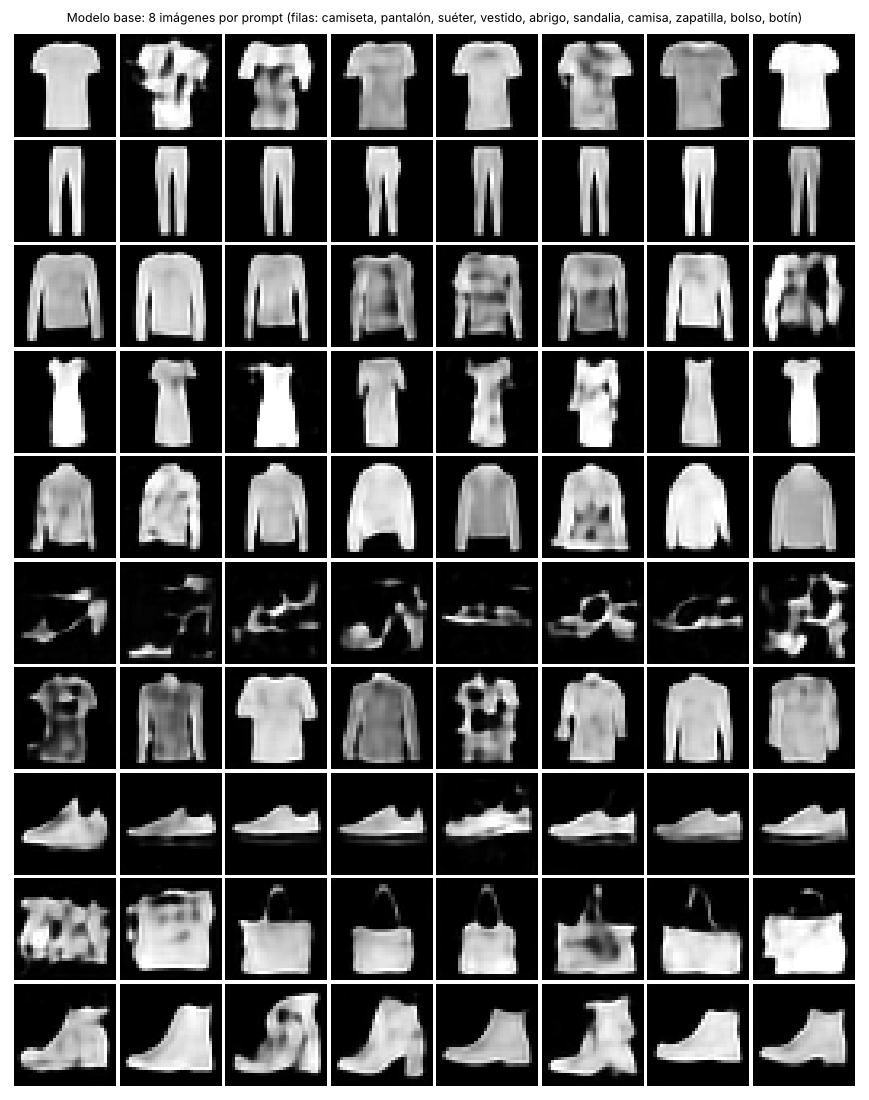

In [7]:
pipe = StableDiffusionPipeline(vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet,
                               scheduler=DDIMScheduler.from_config(noise_scheduler.config, clip_sample=False, set_alpha_to_one=False),
                               safety_checker=None, feature_extractor=None, requires_safety_checker=False).to(device)
pipe.set_progress_bar_config(disable=True)

def generate(prompts, n=8, seed=0, steps=50, guidance=3.0, lora_scale=None):
    """Genera n imágenes por prompt. Devuelve tensor (len(prompts)*n, 1, 32, 32) en [-1, 1]."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    kw = {} if lora_scale is None else {"cross_attention_kwargs": {"scale": lora_scale}}
    out = pipe([p for p in prompts for _ in range(n)], num_inference_steps=steps, guidance_scale=guidance,
               generator=g, output_type="np", **kw).images
    return torch.tensor(out).permute(0, 3, 1, 2) * 2 - 1

PROMPTS_FM = [f"foto de {c}" for c in CLASES]
t0 = time.time(); base_fm = generate(PROMPTS_FM, n=8); print(f"80 imágenes en {time.time() - t0:.1f} s")
plt.figure(figsize=(8, 10.5)); plt.imshow(grid(base_fm, 8), cmap="gray"); plt.axis("off")
plt.title("Modelo base: 8 imágenes por prompt (filas: " + ", ".join(c.split()[-1] for c in CLASES) + ")", fontsize=8)
plt.tight_layout(); plt.savefig("figures/02_base_generacion.png", bbox_inches="tight"); plt.show()

### Proceso inverso: de ruido a imagen
Se decodifica la predicción de $z_0$ en distintos pasos del muestreo DDIM para «foto de una zapatilla».

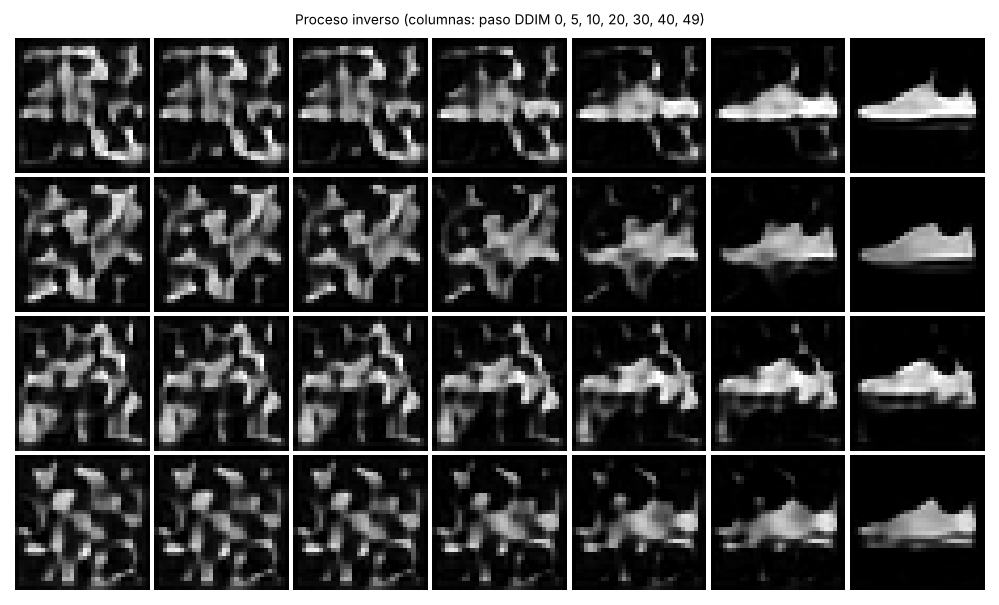

In [8]:
captures = {}
def cb(p, i, t, kw):
    if i in (0, 5, 10, 20, 30, 40, 49):
        captures[i] = kw["latents"].clone()
    return kw
g = torch.Generator(device="cpu").manual_seed(3)
_ = pipe(["foto de una zapatilla"] * 4, num_inference_steps=50, guidance_scale=3.0, generator=g, output_type="np",
         callback_on_step_end=cb, callback_on_step_end_tensor_inputs=["latents"])
with torch.no_grad():
    rev = torch.cat([vae.decode(captures[i] / SCALING).sample.cpu() for i in sorted(captures)])
plt.figure(figsize=(10, 5.6)); plt.imshow(grid(rev.reshape(len(captures), 4, 1, 32, 32).transpose(0, 1).reshape(-1, 1, 32, 32), len(captures)), cmap="gray")
plt.axis("off"); plt.title("Proceso inverso (columnas: paso DDIM " + ", ".join(map(str, sorted(captures))) + ")", fontsize=9)
plt.tight_layout(); plt.savefig("figures/02_difusion_reverse.png", bbox_inches="tight"); plt.show()

## 7. Evaluador automático
Para medir objetivamente qué genera el modelo se entrena una pequeña CNN que clasifica imágenes reales de 32×32 en **11 clases**: las 10 prendas y «rostro». Con ella se mide:
* **Adherencia al prompt:** % de imágenes generadas para «foto de X» que el evaluador reconoce como X.
* **Aprendizaje del concepto:** % de imágenes de «foto de un rostro» reconocidas como rostro.

In [9]:
clf = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 11)).to(device)
all_x = torch.tensor(np.pad(imgs, ((0, 0), (2, 2), (2, 2))), dtype=torch.float32)[:, None] / 127.5 - 1      # 60 000 prendas
Xc = torch.cat([all_x, face_ft.repeat(30, 1, 1, 1)]); Yc = torch.cat([torch.tensor(labs.astype(np.int64)), torch.full((6000,), 10)])
opt_c = torch.optim.Adam(clf.parameters(), 1e-3)
for ep in range(3):
    perm = torch.randperm(len(Xc))
    for b in range(0, len(Xc), 128):
        bi = perm[b:b + 128]; x = Xc[bi].to(device)
        x = torch.where(torch.rand(len(bi), 1, 1, 1, device=device) < 0.5, x.flip(-1), x)
        loss = F.cross_entropy(clf(x), Yc[bi].to(device)); opt_c.zero_grad(); loss.backward(); opt_c.step()
clf.eval()
te_img = np.frombuffer(gzip.open(urllib.request.urlretrieve(f"{FM}/t10k-images-idx3-ubyte.gz", "data/t10k-images-idx3-ubyte.gz")[0]).read(), np.uint8, offset=16).reshape(-1, 28, 28)
te_lab = np.frombuffer(gzip.open(urllib.request.urlretrieve(f"{FM}/t10k-labels-idx1-ubyte.gz", "data/t10k-labels-idx1-ubyte.gz")[0]).read(), np.uint8, offset=8)
te_x = torch.tensor(np.pad(te_img, ((0, 0), (2, 2), (2, 2))), dtype=torch.float32)[:, None] / 127.5 - 1
@torch.no_grad()
def classify(x): return torch.cat([clf(x[b:b + 512].to(device)).argmax(1).cpu() for b in range(0, len(x), 512)])
acc_fm = (classify(te_x) == torch.tensor(te_lab.astype(np.int64))).float().mean().item()
acc_face = (classify(face_test) == 10).float().mean().item()
print(f"Evaluador — exactitud en Fashion-MNIST test: {acc_fm:.3f} | rostros de personas no usadas (21-40): {acc_face:.3f}")

def adherence(imgs, n=8):
    pred = classify(imgs).reshape(-1, n)
    return [(pred[i] == i).float().mean().item() for i in range(len(pred))]
adh_base = adherence(base_fm)
print("Adherencia al prompt del modelo base:", np.round(adh_base, 2), "→ media", round(float(np.mean(adh_base)), 3))

Evaluador — exactitud en Fashion-MNIST test: 0.777 | rostros de personas no usadas (21-40): 1.000
Adherencia al prompt del modelo base: [1.   1.   0.88 1.   0.88 1.   0.12 1.   0.88 1.  ] → media 0.875


## 8. Fine-tuning con LoRA (procedimiento de Stable Diffusion)
**LoRA** (*Low-Rank Adaptation*; Hu et al., 2022) congela los pesos originales W y aprende una corrección de bajo rango: $W' = W + \frac{\alpha}{r} B A$, con $A \in \mathbb{R}^{r\times k}$, $B \in \mathbb{R}^{d\times r}$ y r pequeño. Igual que en el script oficial de `diffusers`, los adaptadores se insertan en las proyecciones de atención de la U-Net (`to_q`, `to_k`, `to_v`, `to_out.0`) con `unet.add_adapter(LoraConfig(...))`. Se usa rango r = 16 porque la U-Net en miniatura es muy pequeña (en SD 1.5 basta r = 4–8). El VAE, el codificador de texto y la U-Net base quedan **congelados**.

Para no «olvidar» lo aprendido, cada lote mezcla un 50 % de rostros con un 50 % de prendas con sus descripciones originales (*prior preservation*, la misma idea que usa DreamBooth). Así el adaptador aprende a responder a «rostro» sin alterar la respuesta a las demás descripciones.

Parámetros entrenables LoRA: 44,032 de 847,236 (5.20 % de la U-Net)


paso  500: pérdida = 0.1305 (53 s)


paso 1000: pérdida = 0.1208 (106 s)


paso 1500: pérdida = 0.1168 (158 s)


paso 2000: pérdida = 0.1115 (211 s)


paso 2500: pérdida = 0.1131 (263 s)


paso 3000: pérdida = 0.1114 (315 s)


paso 3500: pérdida = 0.1097 (368 s)


paso 4000: pérdida = 0.1090 (419 s)
Pesos LoRA guardados: ['pytorch_lora_weights.safetensors'] (181 KB)


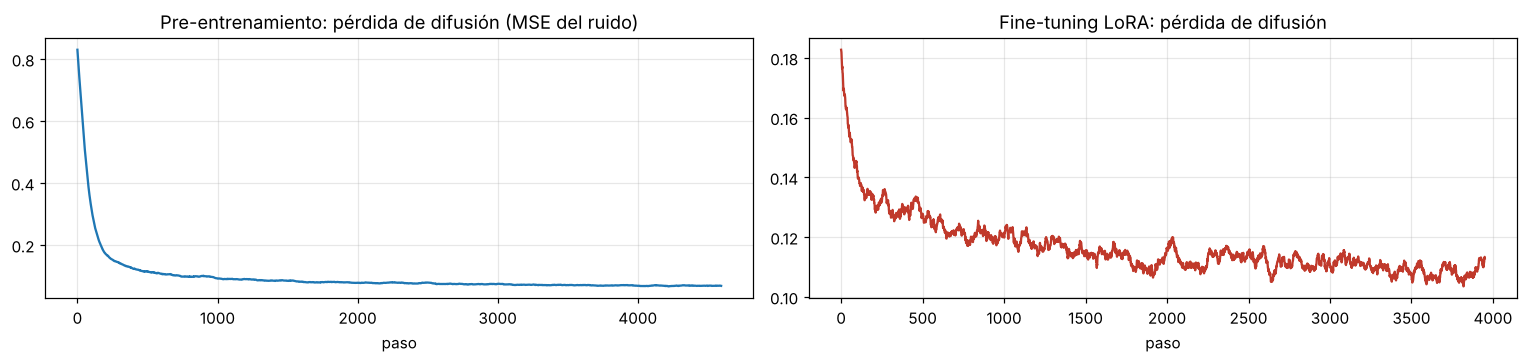

In [10]:
gen_before = generate(["foto de un rostro"], n=16, seed=1)
face_before = (classify(gen_before) == 10).float().mean().item()

unet.requires_grad_(False); text_encoder.requires_grad_(False)
unet.add_adapter(LoraConfig(r=16, lora_alpha=16, init_lora_weights="gaussian", target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
lora_params = [p for p in unet.parameters() if p.requires_grad]
n_lora, n_unet = sum(p.numel() for p in lora_params), sum(p.numel() for p in unet.parameters())
print(f"Parámetros entrenables LoRA: {n_lora:,} de {n_unet:,} ({100 * n_lora / n_unet:.2f} % de la U-Net)")

lat_face_s = encode(face_ft) * SCALING
ids_face = tokenize(["foto de un rostro"]).repeat(len(lat_face_s), 1)
opt = torch.optim.AdamW(lora_params, lr=5e-4, weight_decay=1e-2)
FT_STEPS, PRIOR = 4000, 0.5
ft_hist, t0 = [], time.time()
unet.train()
for step in range(1, FT_STEPS + 1):
    n_face = int(BS * (1 - PRIOR))
    bi = torch.randint(0, len(lat_face_s), (n_face,)); bj = torch.randint(0, len(lat_fm_s), (BS - n_face,))
    lat_f = lat_face_s[bi]; lat_f = torch.where(torch.rand(n_face, 1, 1, 1, device=lat_f.device) < 0.5, lat_f.flip(-1), lat_f)   # espejo
    lat = torch.cat([lat_f, lat_fm_s[bj]])
    ids = torch.cat([ids_face[bi], ids_fm[bj]]).clone(); drop = torch.rand(BS) < 0.1; ids[drop] = ids_empty
    loss = diffusion_step(unet, lat, ids.to(device), train_text=False)
    opt.zero_grad(); loss.backward(); opt.step(); ft_hist.append(loss.item())
    if step % 500 == 0: print(f"paso {step:4d}: pérdida = {np.mean(ft_hist[-300:]):.4f} ({time.time() - t0:.0f} s)")
ft_time = time.time() - t0
unet.eval()
StableDiffusionPipeline.save_lora_weights("modelos/lora_rostro", unet_lora_layers=get_peft_model_state_dict(unet), safe_serialization=True)
print("Pesos LoRA guardados:", os.listdir("modelos/lora_rostro"), f"({os.path.getsize('modelos/lora_rostro/pytorch_lora_weights.safetensors') / 1024:.0f} KB)")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.4))
def sm(v, k=100): return np.convolve(v, np.ones(k) / k, mode="valid")
ax[0].plot(sm(pre_hist)); ax[0].set_title("Pre-entrenamiento: pérdida de difusión (MSE del ruido)"); ax[0].set_xlabel("paso")
ax[1].plot(sm(ft_hist, 50), c="#c0392b"); ax[1].set_title("Fine-tuning LoRA: pérdida de difusión"); ax[1].set_xlabel("paso")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/02_perdidas.png", bbox_inches="tight"); plt.show()

## 9. Resultados: antes y después del fine-tuning

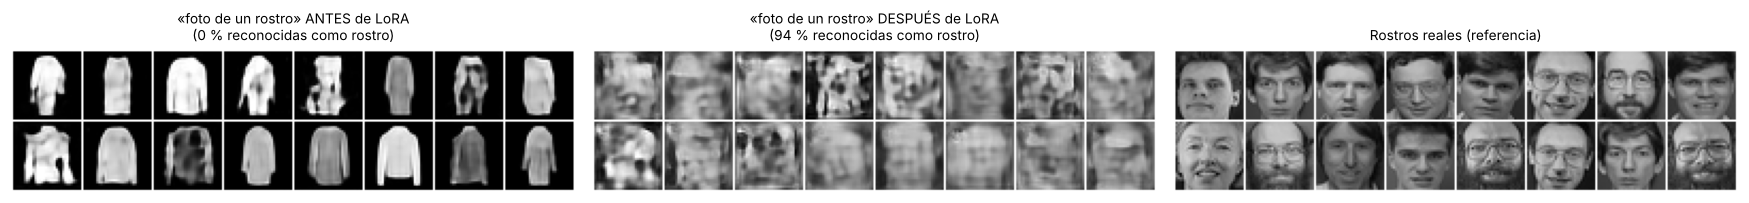

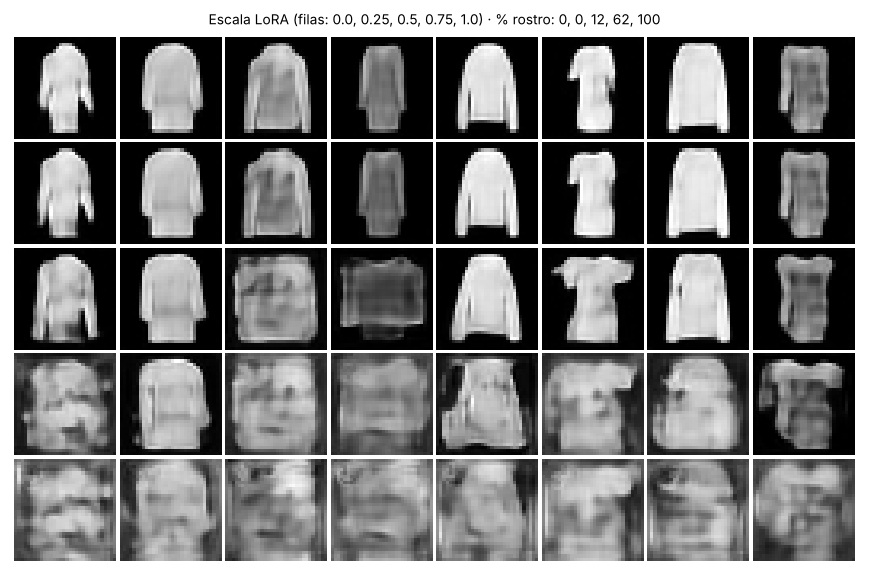

In [11]:
gen_after = generate(["foto de un rostro"], n=16, seed=1)
face_after = (classify(gen_after) == 10).float().mean().item()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
ax[0].imshow(grid(gen_before, 8), cmap="gray"); ax[0].set_title(f"«foto de un rostro» ANTES de LoRA\n({100 * face_before:.0f} % reconocidas como rostro)", fontsize=9)
ax[1].imshow(grid(gen_after, 8), cmap="gray"); ax[1].set_title(f"«foto de un rostro» DESPUÉS de LoRA\n({100 * face_after:.0f} % reconocidas como rostro)", fontsize=9)
ax[2].imshow(grid(face_test[torch.randperm(200)[:16]], 8), cmap="gray"); ax[2].set_title("Rostros reales (referencia)", fontsize=9)
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("figures/02_antes_despues.png", bbox_inches="tight"); plt.show()

scales = [0.0, 0.25, 0.5, 0.75, 1.0]
scale_imgs, scale_face = [], []
for s in scales:
    im = generate(["foto de un rostro"], n=8, seed=5, lora_scale=s); scale_imgs.append(im)
    scale_face.append((classify(im) == 10).float().mean().item())
plt.figure(figsize=(8, 5.4)); plt.imshow(grid(torch.cat(scale_imgs), 8), cmap="gray"); plt.axis("off")
plt.title("Escala LoRA (filas: " + ", ".join(map(str, scales)) + ") · % rostro: " + ", ".join(f"{100 * v:.0f}" for v in scale_face), fontsize=9)
plt.tight_layout(); plt.savefig("figures/02_escala_lora.png", bbox_inches="tight"); plt.show()

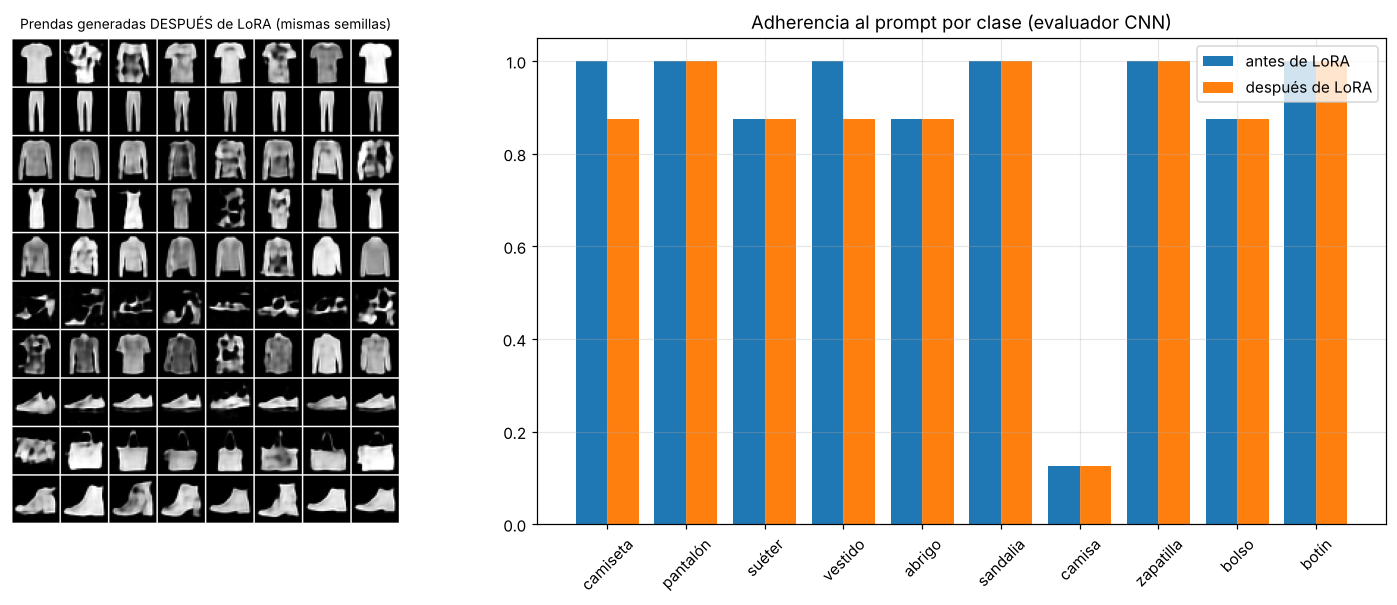

{
 "params_vae": 241749,
 "params_text": 74752,
 "params_unet": 803204,
 "params_lora": 44032,
 "lora_pct": 5.1971,
 "lora_kb": 180.8438,
 "vae_mae_prendas": 6.7737,
 "vae_mae_rostros": 12.4726,
 "scaling_factor": 0.7721,
 "pre_epocas": 15,
 "pre_min": 10.7141,
 "pre_loss_ini": 0.8298,
 "pre_loss_fin": 0.0685,
 "ft_pasos": 4000,
 "ft_min": 6.9878,
 "ft_loss_ini": 0.1827,
 "ft_loss_fin": 0.109,
 "eval_acc_fashion": 0.777,
 "eval_acc_rostros": 1.0,
 "rostro_antes": 0.0,
 "rostro_despues": 0.9375,
 "adherencia_antes": 0.875,
 "adherencia_despues": 0.85,
 "nn_generado_entrenamiento": 41.8949,
 "nn_real_nuevo_entrenamiento": 36.9527
}


In [12]:
after_fm = generate(PROMPTS_FM, n=8)
adh_after = adherence(after_fm)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].imshow(grid(after_fm, 8), cmap="gray"); ax[0].axis("off"); ax[0].set_title("Prendas generadas DESPUÉS de LoRA (mismas semillas)", fontsize=9)
x = np.arange(10)
ax[1].bar(x - 0.2, adh_base, 0.4, label="antes de LoRA"); ax[1].bar(x + 0.2, adh_after, 0.4, label="después de LoRA")
ax[1].set_xticks(x); ax[1].set_xticklabels([c.split()[-1] for c in CLASES], rotation=45); ax[1].set_ylim(0, 1.05)
ax[1].set_title("Adherencia al prompt por clase (evaluador CNN)"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/02_preservacion.png", bbox_inches="tight"); plt.show()

# memorización: distancia de los rostros generados al rostro de entrenamiento más cercano
d_gen = torch.cdist(gen_after.reshape(16, -1), face_ft.reshape(200, -1)).min(1).values
d_real = torch.cdist(face_test.reshape(200, -1), face_ft.reshape(200, -1)).min(1).values
summary = {"params_vae": sum(p.numel() for p in vae.parameters()), "params_text": sum(p.numel() for p in text_encoder.parameters()),
           "params_unet": n_unet - n_lora, "params_lora": n_lora, "lora_pct": 100 * n_lora / n_unet,
           "lora_kb": os.path.getsize("modelos/lora_rostro/pytorch_lora_weights.safetensors") / 1024,
           "vae_mae_prendas": mae_fm, "vae_mae_rostros": mae_face, "scaling_factor": SCALING,
           "pre_epocas": PRE_EPOCHS, "pre_min": pre_time / 60, "pre_loss_ini": float(np.mean(pre_hist[:100])), "pre_loss_fin": float(np.mean(pre_hist[-300:])),
           "ft_pasos": FT_STEPS, "ft_min": ft_time / 60, "ft_loss_ini": float(np.mean(ft_hist[:50])), "ft_loss_fin": float(np.mean(ft_hist[-300:])),
           "eval_acc_fashion": acc_fm, "eval_acc_rostros": acc_face,
           "rostro_antes": face_before, "rostro_despues": face_after, "escala_lora": dict(zip(map(str, scales), scale_face)),
           "adherencia_antes": float(np.mean(adh_base)), "adherencia_despues": float(np.mean(adh_after)),
           "adherencia_clase_antes": adh_base, "adherencia_clase_despues": adh_after,
           "nn_generado_entrenamiento": d_gen.mean().item() * 127.5 / 32, "nn_real_nuevo_entrenamiento": d_real.mean().item() * 127.5 / 32}
json.dump(summary, open("results/02_mini_sd.json", "w"), indent=2)
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in summary.items() if not isinstance(v, (list, dict))}, indent=1))

## 10. Recarga del LoRA en un pipeline limpio
Así se distribuye un fine-tuning de Stable Diffusion: un archivo de pocos KB/MB que se carga sobre el modelo base con `load_lora_weights`.

In [13]:
unet.disable_adapters() if hasattr(unet, "disable_adapters") else None
pipe.unload_lora_weights() if hasattr(pipe, "unload_lora_weights") else None
check_off = generate(["foto de un rostro"], n=8, seed=1)
pipe.load_lora_weights("modelos/lora_rostro", adapter_name="rostro")
check_on = generate(["foto de un rostro"], n=8, seed=1)
print(f"Sin LoRA: {100 * (classify(check_off) == 10).float().mean():.0f} % rostro | con LoRA recargado: {100 * (classify(check_on) == 10).float().mean():.0f} % rostro")

Sin LoRA: 0 % rostro | con LoRA recargado: 88 % rostro


## 11. Análisis
* **Componentes de Stable Diffusion con diffusers.** Con `AutoencoderKL`, `CLIPTokenizer`/`CLIPTextModel`, `UNet2DConditionModel`, `DDPMScheduler`/`DDIMScheduler` y `StableDiffusionPipeline` se construyó y entrenó un modelo de difusión latente completo en 18 minutos de CPU.
* **VAE y espacio latente.** Cada imagen de 32×32 se comprime a un latente de 8×8×4. El error de reconstrucción es de 6.8 niveles de gris (de 255) en prendas y de 12.5 en rostros de personas que el VAE nunca vio: el compresor generaliza a imágenes nuevas.
* **Modelo base.** La pérdida de difusión bajó de 0.83 a 0.068 en 15 épocas. El modelo genera la prenda pedida en el 87.5 % de los casos según el evaluador; la única clase difícil es «camisa» (12 %), que se confunde con camiseta y suéter, como ocurre también con imágenes reales.
* **Fine-tuning LoRA.** Entrenando sólo 44 032 parámetros (5.2 % de la U-Net; archivo de 181 KB), el modelo aprendió un concepto que no conocía: «foto de un rostro» pasó de 0 % a **94 %** de imágenes reconocidas como rostro. Gracias a la mezcla con prendas (*prior preservation*) la adherencia en las demás descripciones casi no cambió (87.5 % → 85 %).
* **Escala LoRA.** El efecto es gradual y controlable: con escala 0 y 0.25 no aparecen rostros, con 0.5 el 12 %, con 0.75 el 62 % y con 1.0 el 100 %. Recargado con `load_lora_weights`, el adaptador vuelve a producir rostros (88 %).
* **Calidad.** Los rostros generados son borrosos y de baja definición: tienen la distribución de luces y sombras de una cara (ojos, nariz, contorno), pero no detalles nítidos. Es la consecuencia esperada de una U-Net de 0.8 M parámetros, 32×32 píxeles y 200 imágenes de entrenamiento. No son copias: están más lejos de los rostros de entrenamiento (41.9) que un rostro real nuevo (37.0).
* **Escala real.** El mismo código, con SD 1.5 (860 M parámetros, 512×512 y CLIP pre-entrenado) en una GPU, produce resultados fotorrealistas: es el Notebook 03.